In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

df=pd.read_csv('/content/Airlines.csv')
display(df.head())
df = df.dropna()

# REMOVED 'Length' from features
features = ['Airline', 'Flight', 'AirportFrom', 'AirportTo', 'DayOfWeek', 'Time']
target = 'Delay'

X = df[features].copy()
y = df[target].copy()

,id,Airline,Flight,AirportFrom,AirportTo,DayOfWeek,Time,Length,Delay
0,1,CO,269,SFO,IAH,3,15.0,205.0,1.0
1,2,US,1558,PHX,CLT,3,15.0,222.0,1.0
2,3,AA,2400,LAX,DFW,3,20.0,165.0,1.0
3,4,AA,2466,SFO,DFW,3,20.0,195.0,1.0
4,5,AS,108,ANC,SEA,3,30.0,202.0,0.0


In [4]:
encoders = {}
categorical_columns = ['Airline', 'AirportFrom', 'AirportTo']

for col in categorical_columns:
    le = LabelEncoder()
    X[col] = le.fit_transform(X[col])
    encoders[col] = le

print("Categorical variables encoded successfully.")
display(X.head())

Categorical variables encoded successfully.


,Airline,Flight,AirportFrom,AirportTo,DayOfWeek,Time
0,4,269,251,134,3,15.0
1,14,1558,215,60,3,15.0
2,1,2400,153,80,3,20.0
3,1,2466,251,80,3,20.0
4,2,108,14,250,3,30.0


In [5]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"Training data shape: {X_train.shape}")
print(f"Testing data shape: {X_test.shape}")

rf_model = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)

print("Training the model... this might take a minute.")
rf_model.fit(X_train, y_train)
print("Model training complete!")

Training data shape: (197001, 6)
Testing data shape: (49251, 6)
Training the model... this might take a minute.
Model training complete!


Model Accuracy: 63.37%

Classification Report:
              precision    recall  f1-score   support

         0.0       0.70      0.73      0.71     30767
         1.0       0.51      0.48      0.50     18484

    accuracy                           0.63     49251
   macro avg       0.61      0.60      0.60     49251
weighted avg       0.63      0.63      0.63     49251



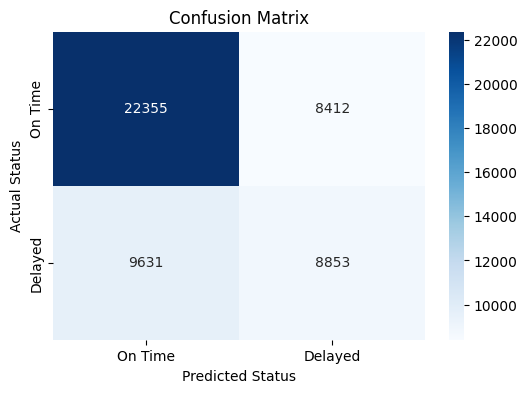

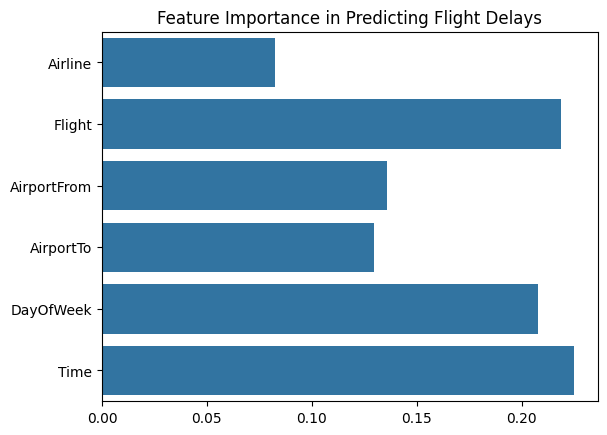

In [6]:
# Make predictions on the test set
y_pred = rf_model.predict(X_test)

# Calculate Accuracy
accuracy = accuracy_score(y_test, y_pred)
print(f"Model Accuracy: {accuracy * 100:.2f}%\n")

# Print Detailed Classification Report (Precision, Recall, F1-Score)
print("Classification Report:")
print(classification_report(y_test, y_pred))

# Plot the Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['On Time', 'Delayed'],
            yticklabels=['On Time', 'Delayed'])
plt.xlabel('Predicted Status')
plt.ylabel('Actual Status')
plt.title('Confusion Matrix')
plt.show()

# Bonus: Feature Importance Plot
importances = rf_model.feature_importances_
sns.barplot(x=importances, y=features)
plt.title('Feature Importance in Predicting Flight Delays')
plt.show()

In [7]:
def predict_flight_status(airline, flight_num, origin, dest, day_of_week_str, time_hhmm):
    """
    Takes user input, encodes it, and returns a delay prediction.
    """
    # 1. Structure the input as a DataFrame

    # Convert Day of Week string to number
    day_mapping = {
        'Monday': 1,
        'Tuesday': 2,
        'Wednesday': 3,
        'Thursday': 4,
        'Friday': 5,
        'Saturday': 6,
        'Sunday': 7
    }
    day_of_week = day_mapping.get(day_of_week_str, None)
    if day_of_week is None:
        return "Error: Invalid Day of Week provided."

    # Convert HH:MM time string to minutes from midnight
    try:
        hours, minutes = map(int, time_hhmm.split(':'))
        time_in_minutes = hours * 60 + minutes
    except ValueError:
        return "Error: Invalid time format. Please use HH:MM (e.g., 18:30)."

    input_data = pd.DataFrame({
        'Airline': [airline],
        'Flight': [flight_num],
        'AirportFrom': [origin],
        'AirportTo': [dest],
        'DayOfWeek': [day_of_week],
        'Time': [time_in_minutes]
    })

    # 2. Encode the categorical inputs using our saved encoders
    try:
        for col in categorical_columns:
            input_data[col] = encoders[col].transform(input_data[col])
    except ValueError as e:
        return f"Error: Unrecognized input for Airline or Airport. Ensure it matches the dataset. Details: {e}"

    # 3. Make the prediction
    prediction = rf_model.predict(input_data)
    probability = rf_model.predict_proba(input_data).max() * 100

    # 4. Format the output
    if prediction[0] == 1:
        return f"🔴 FLIGHT DELAYED ({probability:.1f}% Confidence)"
    else:
        return f"🟢 FLIGHT ON TIME ({probability:.1f}% Confidence)"

# --- Test the Sample Output ---
# Note: Use Airline and Airport codes that actually exist in your chosen dataset
print("\n--- User Input Prediction ---")

test_airline = 'DL'         # Delta Airlines
test_flight_num = 1234
test_origin = 'ATL'         # Atlanta
test_dest = 'JFK'           # New York
test_day = 'Wednesday'      # Changed to string
test_time = '18:30'         # Changed to HH:MM format

result = predict_flight_status(
    test_airline, test_flight_num, test_origin, test_dest, test_day, test_time
)

print(f"Input: Airline={test_airline}, Route={test_origin}->{test_dest}, Time={test_time}")
print(f"Output: {result}")


--- User Input Prediction ---
Input: Airline=DL, Route=ATL->JFK, Time=18:30
Output: 🟢 FLIGHT ON TIME (56.6% Confidence)


In [8]:
import pickle

# Bundle the model and the encoders together into a dictionary
saved_data = {
    'model': rf_model,
    'encoders': encoders
}

# Save it as a .pkl (pickle) file
with open('flight_model.pkl', 'wb') as file:
    pickle.dump(saved_data, file)

print("Model saved successfully!")

Model saved successfully!


In [9]:
# 1. Install Streamlit and localtunnel
!pip install -q streamlit
!npm install localtunnel

⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼⠴
added 22 packages in 4s
⠴
⠴3 packages are looking for funding
⠴  run `npm fund` for details
⠴npm notice
npm notice New major version of npm available! 10.8.2 -> 12.2.3
npm notice Changelog: https://github.com/npm/cli/releases/tag/v12.2.3
npm notice To update run: npm install -g npm@12.2.3
npm notice
⠴

In [ ]:
import gradio as gr
import pandas as pd
import pickle

# 2. Load the trained model and encoders
with open('flight_model.pkl', 'rb') as file:
    data = pickle.load(file)

model = data['model']
encoders = data['encoders']

# Day of week mapping for display and conversion
day_mapping = {
    'Monday': 1,
    'Tuesday': 2,
    'Wednesday': 3,
    'Thursday': 4,
    'Friday': 5,
    'Saturday': 6,
    'Sunday': 7
}

# 3. Define the prediction function
def predict_delay(airline, origin, dest, day_of_week_str, time_hhmm):
    # Convert Day of Week string to number
    day = day_mapping.get(day_of_week_str, None)
    if day is None:
        return "Error: Invalid Day of Week selected."

    # Convert HH:MM time string to minutes from midnight
    try:
        hours, minutes = map(int, time_hhmm.split(':'))
        time_in_minutes = hours * 60 + minutes
    except ValueError:
        return "Error: Invalid time format. Please use HH:MM (e.g., 18:30)."

    # Structure the user input
    input_df = pd.DataFrame({
        'Airline': [airline],
        'Flight': [9999], # Dummy flight number for the model, as per requirement
        'AirportFrom': [origin],
        'AirportTo': [dest],
        'DayOfWeek': [day],
        'Time': [time_in_minutes]
    })

    # Encode the categorical variables
    try:
        input_df['Airline'] = encoders['Airline'].transform(input_df['Airline'])
        input_df['AirportFrom'] = encoders['AirportFrom'].transform(input_df['AirportFrom'])
        input_df['AirportTo'] = encoders['AirportTo'].transform(input_df['AirportTo'])
    except ValueError as e:
        return f"Error: Invalid Airport or Airline selected. Details: {e}"

    # Make prediction
    prediction = model.predict(input_df)[0]
    probability = model.predict_proba(input_df)[0].max() * 100

    # Format output
    if prediction == 1:
        return f"🔴 FLIGHT DELAYED ({probability:.1f}% Confidence)"
    else:
        return f"🟢 FLIGHT ON TIME ({probability:.1f}% Confidence)"

# 4. Build the Web Interface
interface = gr.Interface(
    fn=predict_delay,
    inputs=[
        gr.Dropdown(choices=list(encoders['Airline'].classes_), label="Airline"),
        gr.Dropdown(choices=list(encoders['AirportFrom'].classes_), label="Origin Airport"),
        gr.Dropdown(choices=list(encoders['AirportTo'].classes_), label="Destination Airport"),
        gr.Dropdown(choices=list(day_mapping.keys()), label="Day of Week"), # Dropdown for day names
        gr.Textbox(value="18:30", label="Departure Time (HH:MM)") # Textbox for HH:MM input
    ],
    outputs=gr.Textbox(label="Prediction Result"),
    title="Flight Delay Prediction System",
    flagging_mode='never', # Updated from allow_flagging to flagging_mode
    description="Select your flight details below to predict if your flight will be delayed."
)

# 5. Launch the app with a public link!
interface.launch(
    share=True,
    debug=True,
    theme=gr.themes.Soft(),
    css="footer { display: none !important; }"
)

Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
* Running on public URL: https://2b4af3cb3a5c6a1032.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
